# Tuần 1 — Kiểm toán Schema, Bộ nhớ & Chất lượng Dữ liệu CarbonGlobe

Notebook này thực hiện kiểm toán toàn diện cấu trúc dữ liệu CarbonGlobe (`.npz`/`.npy`) trước khi đưa vào làm sạch và huấn luyện:
1. Nạp cấu hình `configs/pipeline.yaml` và ước tính chi phí RAM (`float64` vs `float32`, tập ML-ready vs toàn cầu 54.152 sites).
2. Kiểm toán tổng thể `x_train`, `y_train` (shape, dtype, NaN/Inf) và đối chiếu độ khớp với `data_stats.npz`.
3. Phân tích phân bố thống kê của **136 kênh đầu vào (`X`)** nhằm phát hiện kênh hằng số, kênh lệch thang đo hoặc có giá trị khuyết.
4. Phân tích chuyên sâu **7 biến mục tiêu (`TREE_BAND`)**: phân vị, độ lệch (skewness) và biểu đồ hộp (boxplot).
5. Khảo sát tính không gian (`mask2d.npy`) và tính chu kỳ mùa (12 tháng).
6. Xuất báo cáo kiểm toán JSON ra `data/interim/`.

## 1. Cấu hình, Nạp dữ liệu & Ước tính RAM

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("..").resolve()
if str(ROOT) not in sys.path:
    sys.path.append(str(ROOT))

from src.dataset import AGES, TREE_BAND, read_pipeline_config, load_ml_ready_npz, load_stats, load_mask2d
from src.profiling import audit_array, audit_targets_summary, save_audit_report
from src.run_sprint1_2 import create_synthetic_carbonglobe_files

cfg = read_pipeline_config(ROOT / "configs/pipeline.yaml")
raw_dir = ROOT / cfg["paths"]["raw_dir"]
glob_dir = raw_dir / cfg["paths"]["global_subdir"]
stat_dir = raw_dir / cfg["paths"]["stats_subdir"]

using_synthetic = False
if not (glob_dir / cfg["carbonglobe"]["ml_ready_file"]).exists():
    using_synthetic = True
    create_synthetic_carbonglobe_files(raw_dir, seed=cfg["seed"])

data = load_ml_ready_npz(glob_dir, cfg["carbonglobe"]["ml_ready_file"], max_sites=cfg["subset"]["max_sites"])
stats = load_stats(stat_dir, cfg["carbonglobe"]["stats_file"])
mask2d = load_mask2d(stat_dir, cfg["carbonglobe"]["mask_file"])

# Ước tính bộ nhớ cho toàn cầu (54,152 sites) vs ML-ready (3,373 sites)
mem_table = pd.DataFrame([
    {"Tập dữ liệu": "Global X (54,152 x 40 x 12 x 136)", "float64 (GB)": round(54152*40*12*136*8/1e9, 2), "float32 (GB)": round(54152*40*12*136*4/1e9, 2)},
    {"Tập dữ liệu": "ML-ready x_train (3,373 x 40 x 12 x 136)", "float64 (GB)": round(3373*40*12*136*8/1e9, 2), "float32 (GB)": round(3373*40*12*136*4/1e9, 2)},
    {"Tập dữ liệu": "ML-ready y_train (15 x 3,373 x 41 x 12 x 7)", "float64 (GB)": round(15*3373*41*12*7*8/1e9, 2), "float32 (GB)": round(15*3373*41*12*7*4/1e9, 2)},
])
print(f"Chế độ dữ liệu hiện tại: {'Synthetic fallback' if using_synthetic else 'Real Kaggle / Local'}")
print(f"x_train: {data['x_train'].shape} | y_train: {data['y_train'].shape} | mask2d: {mask2d.shape}")
display(mem_table)

Chế độ dữ liệu hiện tại: Real Kaggle / Local
x_train: (30, 40, 12, 136) | y_train: (15, 30, 41, 12, 7) | mask2d: (360, 720)
                                   Tập dữ liệu  float64 (GB)  float32 (GB)
0            Global X (54,152 x 40 x 12 x 136)         28.28         14.14
1     ML-ready x_train (3,373 x 40 x 12 x 136)          1.76          0.88
2  ML-ready y_train (15 x 3,373 x 41 x 12 x 7)          1.39          0.70


## 2. Kiểm toán tổng thể mảng & Đối chiếu `data_stats.npz`
Kiểm tra xem thống kê chuẩn hóa cung cấp sẵn trong `data_stats.npz` có khớp với phân phối thực tế của `x_train` và `y_train` hay không.

In [2]:
audit_x = audit_array(data["x_train"], "x_train")
audit_y = audit_array(data["y_train"], "y_train")
display(pd.DataFrame([audit_x, audit_y]))

# Đối chiếu y_mean / y_std trong data_stats.npz với giá trị tính trực tiếp
emp_y_mean = np.nanmean(data["y_train"], axis=(0, 1, 2, 3))
emp_y_std = np.nanstd(data["y_train"], axis=(0, 1, 2, 3))
stats_check = pd.DataFrame({
    "target": TREE_BAND,
    "stats_mean": np.round(stats["y_mean"], 3),
    "empirical_mean": np.round(emp_y_mean, 3),
    "stats_std": np.round(stats["y_std"], 3),
    "empirical_std": np.round(emp_y_std, 3),
    "abs_mean_diff": np.round(np.abs(stats["y_mean"] - emp_y_mean), 4),
})
display(stats_check)

      name                shape    dtype  memory_mb  nan_count  inf_count  nan_ratio      min        max     mean      std
0  x_train    [30, 40, 12, 136]  float32      7.834          2          0   0.000001 -10.4287    40.7383  15.0032   5.1157
1  y_train  [15, 30, 41, 12, 7]  float32      6.199          0          0   0.000000   0.0000  5000.0000  27.1817  36.1059
   target  stats_mean  empirical_mean  stats_std  empirical_std  abs_mean_diff
0  height   18.016001       18.016001   8.961000       8.961000            0.0
1     agb   86.486000       86.486000  44.203999      44.203999            0.0
2    soil   57.662998       57.662998  28.667000      28.667000            0.0
3     lai    3.243000        3.243000   1.612000       1.612000            0.0
4     gpp   12.970000       12.970000   6.447000       6.447000            0.0
5     npp    6.488000        6.488000   3.220000       3.220000            0.0
6      rh    5.406000        5.406000   2.687000       2.687000            0.0

## 3. Phân tích 136 kênh đầu vào (`X`)
Kiểm tra độ phân tán của `x_mean`, `x_std`, tỷ lệ NaN từng kênh và phát hiện các kênh có biên độ hoặc phương sai bất thường.

Số kênh có NaN > 0: 2
Số kênh gần hằng số (std < 1e-4): 0
Top 8 kênh có độ lệch chuẩn lớn nhất:
   channel  nan_count    mean    std    min        max
15   X_015          0  14.997  5.790 -5.219  39.426998
3    X_003          0  15.022  5.787 -6.319  35.092999
17   X_017          0  14.980  5.776 -7.321  35.307999
6    X_006          0  15.033  5.773 -9.942  35.147999
19   X_019          0  14.945  5.763 -9.521  38.702000
2    X_002          0  14.921  5.762 -8.779  35.981998
16   X_016          0  15.029  5.752 -7.673  39.084000
11   X_011          0  15.050  5.749 -5.477  38.229000


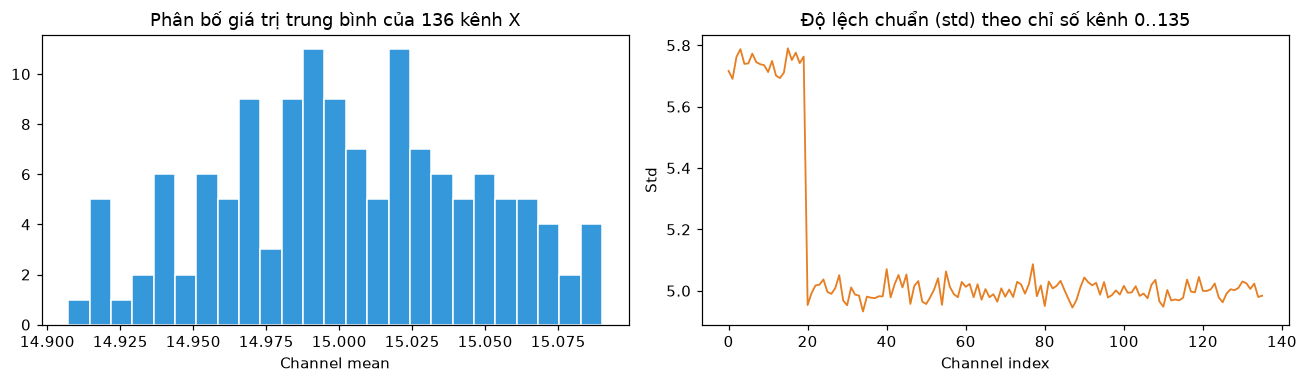

In [3]:
x_arr = data["x_train"]
ch_nan = np.isnan(x_arr).sum(axis=(0, 1, 2))
ch_mean = np.nanmean(x_arr, axis=(0, 1, 2))
ch_std = np.nanstd(x_arr, axis=(0, 1, 2))
ch_min = np.nanmin(x_arr, axis=(0, 1, 2))
ch_max = np.nanmax(x_arr, axis=(0, 1, 2))

x_ch_df = pd.DataFrame({
    "channel": [f"X_{i:03d}" for i in range(x_arr.shape[-1])],
    "nan_count": ch_nan,
    "mean": np.round(ch_mean, 3),
    "std": np.round(ch_std, 3),
    "min": np.round(ch_min, 3),
    "max": np.round(ch_max, 3),
})

print("Số kênh có NaN > 0:", int((ch_nan > 0).sum()))
print("Số kênh gần hằng số (std < 1e-4):", int((ch_std < 1e-4).sum()))
print("Top 8 kênh có độ lệch chuẩn lớn nhất:")
display(x_ch_df.sort_values("std", ascending=False).head(8))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(ch_mean, bins=25, color="#3498db", edgecolor="white")
axes[0].set_title("Phân bố giá trị trung bình của 136 kênh X")
axes[0].set_xlabel("Channel mean")

axes[1].plot(range(len(ch_std)), ch_std, color="#e67e22", linewidth=1.2)
axes[1].set_title("Độ lệch chuẩn (std) theo chỉ số kênh 0..135")
axes[1].set_xlabel("Channel index"); axes[1].set_ylabel("Std")
plt.tight_layout()
plt.show()

## 4. Phân tích chuyên sâu 7 biến mục tiêu (`TREE_BAND`)
Tính bảng phân vị chi tiết (`min`, `p05`, `p25`, `p50`, `p75`, `p95`, `max`, `skewness`) và trực quan hóa bằng boxplot sau khi chuẩn hóa về cùng thang đo để so sánh độ lệch và đuôi ngoại lai.

        nan  min     p05     p50      p95       max    mean     std   skew
target                                                                    
height    0  0.0   5.405  17.031   34.243    54.801  18.016   8.961  0.510
agb       0  0.0  26.016  81.741  164.300  5000.000  86.486  44.205  6.668
soil      0  0.0  17.288  54.572  109.672   171.756  57.663  28.667  0.507
lai       0  0.0   0.975   3.063    6.170     9.878   3.243   1.612  0.511
gpp       0  0.0   3.883  12.255   24.649    40.226  12.970   6.448  0.507
npp       0  0.0   1.955   6.134   12.339    19.522   6.488   3.221  0.510
rh        0  0.0   1.624   5.114   10.287    16.391   5.406   2.687  0.511


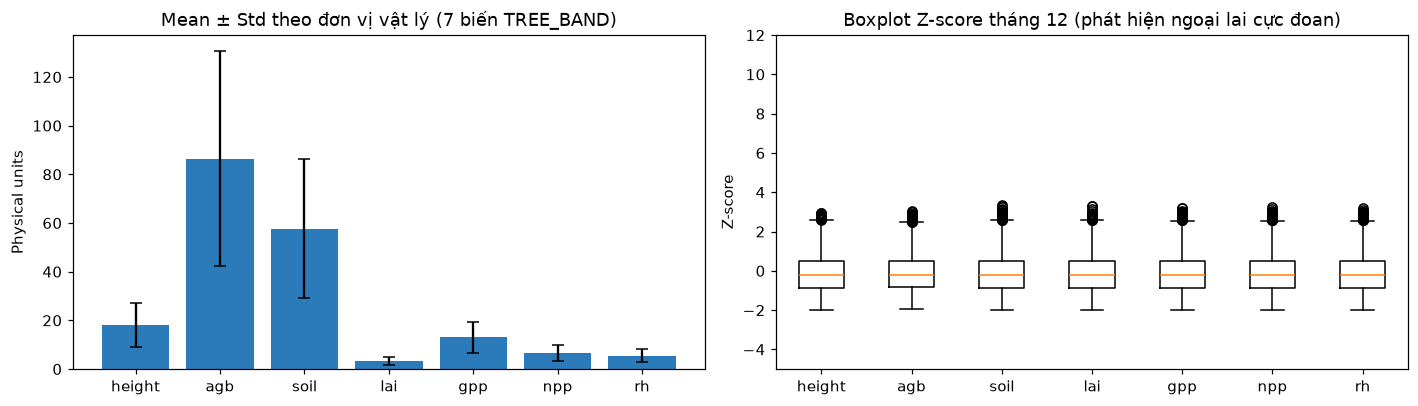

In [4]:
rows = []
y_arr = data["y_train"]
for k, name in enumerate(TREE_BAND):
    vals = y_arr[..., k].ravel()
    fin = vals[np.isfinite(vals)]
    s = pd.Series(fin)
    rows.append({
        "target": name,
        "nan": int(np.isnan(vals).sum()),
        "min": round(float(fin.min()), 3),
        "p05": round(float(np.percentile(fin, 5)), 3),
        "p50": round(float(np.percentile(fin, 50)), 3),
        "p95": round(float(np.percentile(fin, 95)), 3),
        "max": round(float(fin.max()), 3),
        "mean": round(float(fin.mean()), 3),
        "std": round(float(fin.std()), 3),
        "skew": round(float(s.skew()), 3),
    })
target_detail_df = pd.DataFrame(rows).set_index("target")
display(target_detail_df)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
axes[0].bar(target_detail_df.index, target_detail_df["mean"], yerr=target_detail_df["std"], capsize=4, color="#2b7bba")
axes[0].set_title("Mean ± Std theo đơn vị vật lý (7 biến TREE_BAND)")
axes[0].set_ylabel("Physical units")

# Boxplot trên không gian chuẩn hóa để soi ngoại lai
y_z_sample = [(y_arr[:, :, :, 11, k].ravel() - stats["y_mean"][k]) / stats["y_std"][k] for k in range(len(TREE_BAND))]
axes[1].boxplot(y_z_sample, tick_labels=TREE_BAND, showfliers=True)
axes[1].set_ylim(-5, 12)
axes[1].set_title("Boxplot Z-score tháng 12 (phát hiện ngoại lai cực đoan)")
axes[1].set_ylabel("Z-score")
plt.tight_layout()
plt.show()

## 5. Kiểm tra mặt nạ không gian (`mask2d`) & Tính chu kỳ mùa (12 tháng)
Đánh giá tỷ lệ điểm lưới đất liền hợp lệ trên lưới `(360, 720)` và kiểm tra biến thiên theo 12 tháng của nhóm biến khí hậu cùng mục tiêu sinh thái.

mask2d: 40 / 259,200 ô hợp lệ (0.02%)


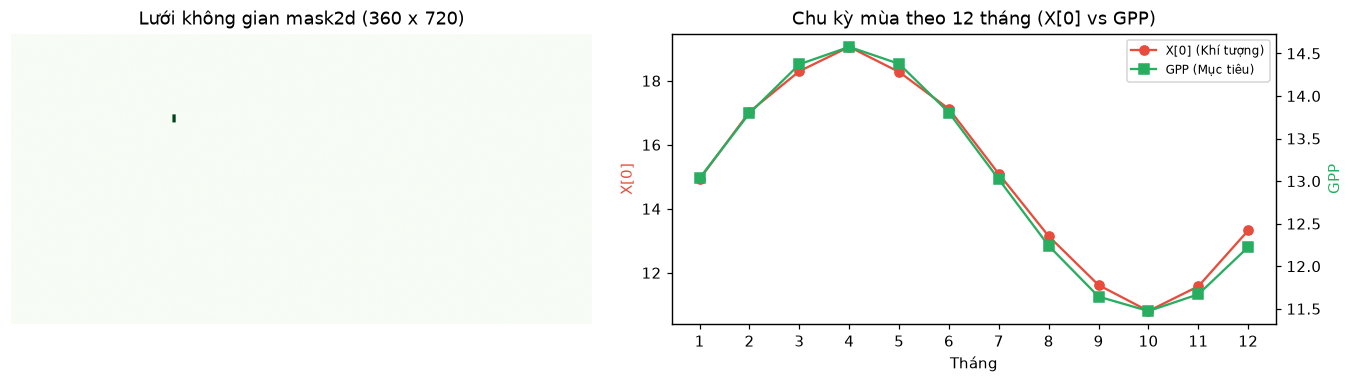

In [5]:
valid_cells = int(mask2d.astype(bool).sum())
total_cells = mask2d.size
print(f"mask2d: {valid_cells:,} / {total_cells:,} ô hợp lệ ({valid_cells / total_cells * 100:.2f}%)")

months = np.arange(1, 13)
x_season = np.nanmean(x_arr[:, :, :, 0], axis=(0, 1))   # Kênh khí tượng 0
gpp_season = np.nanmean(y_arr[:, :, 1:, :, TREE_BAND.index("gpp")], axis=(0, 1, 2))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
axes[0].imshow(mask2d, cmap="Greens", origin="upper")
axes[0].set_title("Lưới không gian mask2d (360 x 720)")
axes[0].axis("off")

ax_r = axes[1].twinx()
l1 = axes[1].plot(months, x_season, marker="o", color="#e74c3c", label="X[0] (Khí tượng)")
l2 = ax_r.plot(months, gpp_season, marker="s", color="#27ae60", label="GPP (Mục tiêu)")
axes[1].set_title("Chu kỳ mùa theo 12 tháng (X[0] vs GPP)")
axes[1].set_xlabel("Tháng"); axes[1].set_xticks(months)
axes[1].set_ylabel("X[0]", color="#e74c3c"); ax_r.set_ylabel("GPP", color="#27ae60")
lines = l1 + l2
axes[1].legend(lines, [l.get_label() for l in lines], loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()

## 6. Lưu báo cáo kiểm toán JSON & Kết luận Tuần 1

In [6]:
report = {
    "source_mode": "synthetic" if using_synthetic else "real",
    "x_train_audit": audit_x,
    "y_train_audit": audit_y,
    "mask2d_valid_sites": valid_cells,
    "target_physical_summary": audit_targets_summary(y_arr, TREE_BAND),
}
out_json = save_audit_report(report, ROOT / cfg["paths"]["interim_dir"] / "notebook_audit_report.json")
print("Đã lưu báo cáo kiểm toán tại:", out_json)
print("Kết luận: Dữ liệu cần chuẩn hóa Z-score, thay thế NaN và cắt ngoại lai cực đoan (như giá trị 5000 ở agb) trước khi tạo đặc trưng ở Tuần 2.")

Đã lưu báo cáo kiểm toán tại: C:\Users\Phuong Linh\OneDrive\Desktop\project-khdl\data\interim\notebook_audit_report.json
Kết luận: Dữ liệu cần chuẩn hóa Z-score, thay thế NaN và cắt ngoại lai cực đoan (như giá trị 5000 ở agb) trước khi tạo đặc trưng ở Tuần 2.
